In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("D:/DATA/aitpune/college study thingy/ml/dataset/sales_data_sample.csv", encoding='latin1')
print(df.shape)
df.head()

(2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
print("Column Names: ")
print(df.columns)

Column Names: 
Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID',
       'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE',
       'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE',
       'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='str')


In [4]:
print("dataset information")
df.info()

dataset information
<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null   

In [5]:
print("missing values")
df.isnull().sum()

missing values


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [6]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]]
X.head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


In [7]:
X.isnull().sum()

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  0.89673966 -0.14224584]]


In [9]:
wcss = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i, random_state = 42, n_init=10)
    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

In [10]:
print(wcss)

[11291.999999999996, 6741.690574808542, 4766.014280081645, 3934.8941211949505, 3348.2685270796583, 2858.818306188108, 2548.535972515337, 2350.660048014792, 2169.9672182365052, 2019.752998176958]


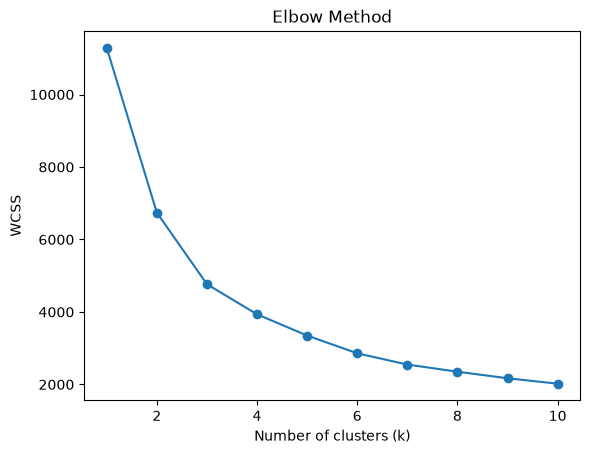

In [11]:
plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')

plt.show()

In [12]:
for i in range(1, len(wcss)):
    reduction = ((wcss[i-1] - wcss[i]) / wcss[i-1]) * 100

    print("Clusters:", i, "to", i+1)
    print("WCSS:", wcss[i])
    print("Reduction:", reduction, "%")
    print()

Clusters: 1 to 2
WCSS: 6741.690574808542
Reduction: 40.29675367686376 %

Clusters: 2 to 3
WCSS: 4766.014280081645
Reduction: 29.30535409188525 %

Clusters: 3 to 4
WCSS: 3934.8941211949505
Reduction: 17.438473954225266 %

Clusters: 4 to 5
WCSS: 3348.2685270796583
Reduction: 14.908294252581959 %

Clusters: 5 to 6
WCSS: 2858.818306188108
Reduction: 14.61800978425246 %

Clusters: 6 to 7
WCSS: 2548.535972515337
Reduction: 10.853517098345973 %

Clusters: 7 to 8
WCSS: 2350.660048014792
Reduction: 7.764297880608161 %

Clusters: 8 to 9
WCSS: 2169.9672182365052
Reduction: 7.6868975558966035 %

Clusters: 9 to 10
WCSS: 2019.752998176958
Reduction: 6.9224188640796 %



In [13]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

df['KMeans_Cluster'] = kmeans.labels_

In [14]:
df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP', 'KMeans_Cluster']].head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,KMeans_Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,1
3,45,83.26,3746.70,95,1
4,49,100.00,5205.27,95,1


In [15]:
print(df['KMeans_Cluster'].value_counts())

KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


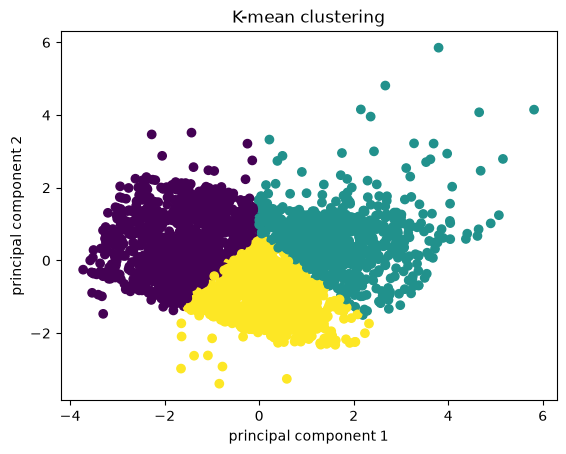

In [16]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['KMeans_Cluster'],
    cmap='viridis'
)

plt.title("K-mean clustering")
plt.xlabel("principal component 1")
plt.ylabel("principal component 2")

plt.show()

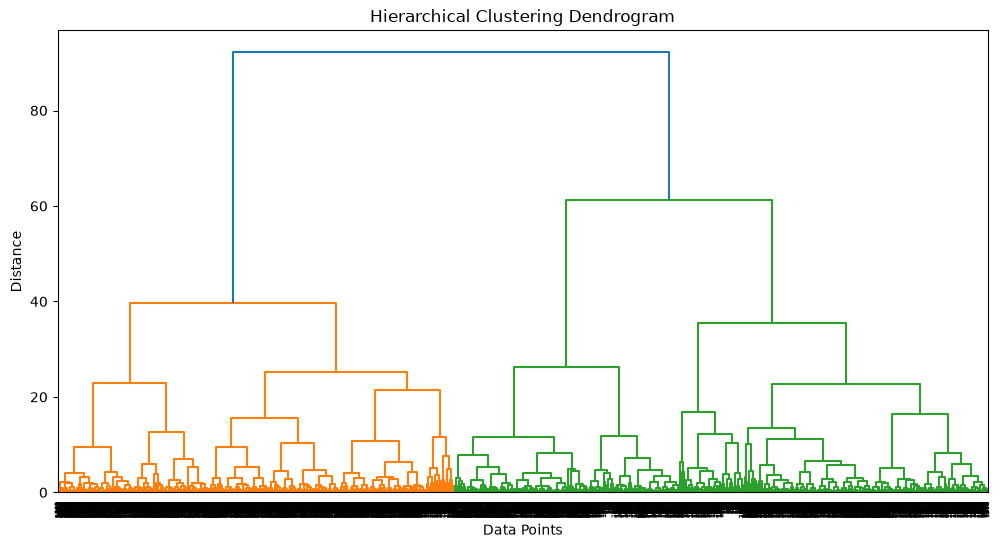

In [17]:
plt.figure(figsize=(12,6))
Z = linkage(X_scaled, method='ward')
dendrogram(Z)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')

plt.show()

In [18]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)
df['Hierarchical_Cluster'] = hc_labels

In [19]:
print(df['Hierarchical_Cluster'].value_counts())

Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


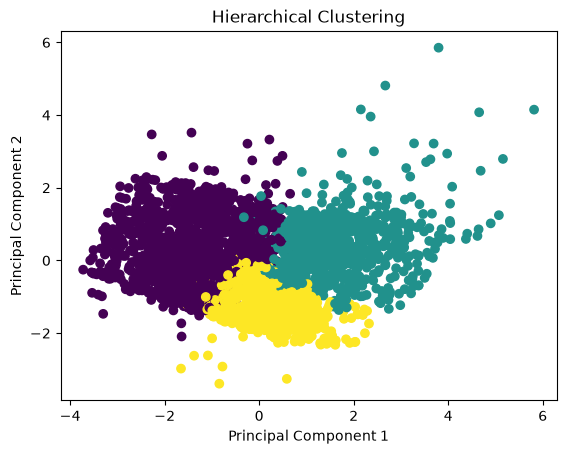

In [20]:
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=df["Hierarchical_Cluster"],
    cmap="viridis"
)

plt.title('Hierarchical Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

In [21]:
print("K-Means Clusters:")
print(df['KMeans_Cluster'].value_counts())

print("\nHierarchical Clusters:")
print(df['Hierarchical_Cluster'].value_counts())

K-Means Clusters:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64

Hierarchical Clusters:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


In [22]:
df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP',
    'KMeans_Cluster', 'Hierarchical_Cluster']].head(10)

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,KMeans_Cluster,Hierarchical_Cluster
0,30,95.70,2871.00,95,2,2
1,34,81.35,2765.90,95,2,2
2,41,94.74,3884.34,95,1,0
3,45,83.26,3746.70,95,1,0
4,49,100.00,5205.27,95,1,1
5,36,96.66,3479.76,95,2,0
6,29,86.13,2497.77,95,2,2
7,48,100.00,5512.32,95,1,1
8,22,98.57,2168.54,95,2,2
9,41,100.00,4708.44,95,1,1
